In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cmocean

In [3]:
from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [4]:
from nese.verify.data import open_anemoi_dataset
from nese.verify.maps import draw_cells

In [5]:
ds = open_anemoi_dataset("base-hpx6-24h/dataset.zarr/")


In [14]:
draw_cells

<function nese.verify.maps.draw_cells(ax, values: xarray.core.dataarray.DataArray, attrs: dict, vmin: float | None = None, vmax: float | None = None, **kwargs: Any) -> matplotlib.collections.PolyCollection>

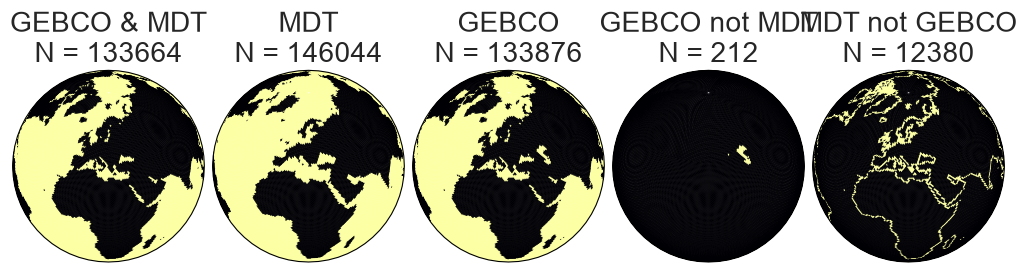

In [58]:
fig, axs = plt.subplots(
    1, 5, figsize=(10, 20),
    subplot_kw={
        "projection": ccrs.Orthographic(
            central_longitude=20,
            central_latitude=40,
        )
    },
)

gebco = ds["land_fraction"] < .1
#gebco = ds["mdt_v"].notnull()
mdt = ds["mdt"].notnull()

gebco_not_mdt = gebco & ~mdt
mdt_not_gebco = mdt & ~gebco
gebco_and_mdt = gebco & mdt

for plotme, label, ax in zip(
    [gebco_and_mdt, mdt, gebco, gebco_not_mdt, mdt_not_gebco],
    ["GEBCO & MDT", "MDT", "GEBCO", "GEBCO not MDT", "MDT not GEBCO"],
    axs,
):
    draw_cells(
        ax=ax,
        values=plotme.isel(time=0),
        attrs=ds.attrs,
    )
    ax.set(title=f"{label}\nN = {plotme.sum().values.astype(int)}")